# Will It Go Viral?
### A Logistic Regression model that estimates whether a short video will go viral, based on its **hook**, **structure** and **content**

**Author:** Gustavo Pugliezi · **Course:** Computer Science · **Tools:** Python, pandas, scikit-learn, matplotlib

---

## Contents
| Step | Framework stage | What happens |
|---|---|---|
| [1](#s1) | Define the problem and label | what "viral" means, as a number |
| [2](#s2) | Define measurable features | 11 characteristics with objective measuring rules |
| [3](#s3) | Receive posts as JSON | 3,000 posts arrive as a JSON file |
| [4](#s4) | Extract feature values | an LLM, or a classroom simulation, fills in the features |
| [5](#s5) | Build the dataset | one row per video, one column per feature |
| [6](#s6) | Separate `X` and `y` | features vs. label |
| [7](#s7) | Train/test split | 80% to learn, 20% kept hidden for the final exam |
| [8](#s8) | Train a Logistic Regression | the model learns one weight per feature |
| [9](#s9) | Evaluate | accuracy and confusion matrix |
| [10](#s10) | Test with brand-new data | posts the model has never seen |
| [11](#s11) | Export as `.pkl` | save the trained model to a file |
| [12](#s12) | Open and run in any application | a separate program loads the `.pkl` and predicts |

## How this notebook is explained
I learned machine learning through one analogy, and I kept it here so the reasoning behind every step is visible.

> **The intern analogy.** Imagine hiring an intern who knows *nothing* about videos. You cannot hand them a rulebook, because nobody knows the exact rules of virality. Instead, you show them thousands of past videos together with what actually happened, and they gradually work out the rules on their own. Then you test them on videos they have never seen.

Every step below has two layers:
- **Intern analogy**: the intuition, in plain language.
- **Technical note**: what the code actually does.

## How to run
**Run → Run All Cells.** The notebook is self-contained: it works in Jupyter Lab, VS Code or Google Colab, needs no other files, and writes everything it produces (`posts.json`, `dataset.csv`, `viral_model.pkl`, …) into the current folder.

In [1]:
%pip install -q numpy pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, pickle, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from datetime import datetime, timedelta

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42  # fixes every random draw, so the notebook gives the same results every time

INK, PAPER, RED, GREY = "#15171c", "#f8f9f6", "#e8341c", "#8a8f96"
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "figure.dpi": 110})

print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")
print("Working folder:", os.getcwd())

Python 3.13.18 | scikit-learn 1.9.1 | pandas 3.0.5
Working folder: /home/user/SITE/notebook


<a id="s1"></a>
## Step 1 — Define the problem and the label

> **Intern analogy.** Before training anyone, you agree on what *success* means. "Viral" cannot be a feeling; it must be something you can check. Otherwise the intern is learning to hit a target that keeps moving.

**Problem:** a creator wants to know, *before posting*, whether a video is likely to go viral.

**Type of problem:** supervised binary classification. *Supervised* because every training example comes with the right answer; *binary* because there are only two answers.

**Label (`y`):** big accounts get many views simply because they are big, so views are compared with the account's size:

$$
\text{viral} = \begin{cases} 1 & \text{if views} \ge 10 \times \text{followers} \\ 0 & \text{otherwise} \end{cases}
$$

An account with 5,000 followers needs at least 50,000 views for the video to count as viral.

In [3]:
VIRAL_MULTIPLIER = 10

def make_label(post):
    return int(post["views"] >= VIRAL_MULTIPLIER * post["followers"])

<a id="s2"></a>
## Step 2 — Define measurable features

> **Intern analogy.** The intern cannot "watch" a video intelligently, so you give them a **checklist** with 11 questions to fill in for every video. Each question must be objective: two different people checking the same video must write down the same answer.

| Group | Feature | Type | Measuring rule |
|---|---|---|---|
| **Hook** | `hook_seconds` | number | timestamp of the first hook sentence in the transcript (no hook → 8) |
| | `hook_type` | category | question, shock, promise, story or none |
| | `face_first_second` | 0/1 | a face appears in the first second |
| | `text_on_screen` | 0/1 | there is written text on screen at the start |
| **Structure** | `duration_s` | number | length of the video in seconds |
| | `cuts_per_10s` | number | (number of cuts ÷ duration) × 10 |
| | `structure` | category | list, tutorial, before_after, storytime or vlog |
| | `has_loop` | 0/1 | the ending loops back to the beginning |
| **Content** | `topic` | category | humor, education, beauty, gaming, cooking or sports |
| | `trending_audio` | 0/1 | the video uses a trending sound |
| | `post_hour` | 0–23 | hour of the day it was posted |

In [4]:
NUMERIC = ["hook_seconds", "duration_s", "cuts_per_10s", "post_hour"]
BINARY = ["face_first_second", "text_on_screen", "has_loop", "trending_audio"]
CATEGORICAL = ["hook_type", "structure", "topic"]
FEATURES = NUMERIC + BINARY + CATEGORICAL
print(f"{len(FEATURES)} features:", FEATURES)

11 features: ['hook_seconds', 'duration_s', 'cuts_per_10s', 'post_hour', 'face_first_second', 'text_on_screen', 'has_loop', 'trending_audio', 'hook_type', 'structure', 'topic']


<a id="s3"></a>
## Step 3 — Receive the posts as JSON

> **Intern analogy.** You hand the intern a pile of 3,000 past videos. They are not video files; they are written descriptions: the caption, what was said and when, and notes about what appears on screen.

**Technical note.** JSON is a plain-text format for structured data. Each post has the fields a platform or a human annotator could provide. `views` and `followers` exist **only** to compute the label.

### 3.1 Simulated data provider
Platforms do not publish things like "seconds until the hook", so the posts are **simulated**. The cell below plays the role of whoever hands us the JSON file: it creates videos whose chance of going viral follows hidden rules inspired by what creators report, **plus a random luck factor**.

> **Important:** from Step 4 on, the notebook never uses these hidden rules. It only reads `posts.json`. Because we know the rules, we can check at the end whether the model rediscovered them from the examples alone. This is how researchers test learning algorithms.

In [5]:
def generate_posts(n=3000, seed=SEED):
    rng = np.random.default_rng(seed)
    pick = lambda options: str(rng.choice(options))

    SUBJECT = {"humor": ["my grandma at the barbecue", "my dramatic dog"],
               "education": ["black holes", "the French Revolution"],
               "beauty": ["the perfect winged eyeliner", "oily skin"],
               "gaming": ["the hardest final boss", "the new map speedrun"],
               "cooking": ["carrot cake", "skillet cheese bread"],
               "sports": ["the weekend's best goal", "keepy-uppy training"]}
    HASHTAGS = {"humor": "#humor #comedy", "education": "#education #learn", "beauty": "#beauty #makeup",
                "gaming": "#gaming #gamer", "cooking": "#recipe #cooking", "sports": "#football #sports"}
    HOOK = {"question": ["Did you know this about {a}?", "Why does nobody talk about {a}?", "Have you ever tried {a}?"],
            "shock": ["STOP EVERYTHING! Look at {a}", "I can't believe {a} looks like this", "This should be illegal: {a}"],
            "promise": ["I'll show you {a} in seconds", "The secret to {a} is this", "After this video you'll master {a}"],
            "story": ["Let me tell you about {a}", "Here's the story of {a}", "So this happened with {a}"]}
    FILLER = ["Hey guys.", "So.", "Okay, let's go.", "Quick one today.", "I'm back again."]
    BODY = ["Then I started.", "Here's how it turned out.", "Yeah.", "Comment below.", "Thanks for watching."]
    CAPTION = {"list": ["3 things about {a}", "Top 5: {a}"], "tutorial": ["How to make {a}", "Step by step: {a}"],
               "before_after": ["Before and after: {a}", "The transformation of {a}"],
               "storytime": ["Storytime: {a}", "I told everything about {a}"], "vlog": ["Vlog: {a}", "A day with {a}"]}
    NOTES = {"face_first_second": (["opens with a close-up of a face", "a face appears in the first second"],
                                   ["opens on the scenery", "no one on screen in the first seconds"]),
             "text_on_screen": (["big text on screen at the start", "caption written over the video"], ["no text on screen"]),
             "has_loop": (["the ending loops back to the start", "ends on the same shot it began with"], [None]),
             "trending_audio": (["uses a trending sound", "viral audio of the moment"], ["original audio"])}

    # hidden rules: how much each characteristic adds to the "virality score"
    HOOK_EFFECT = {"question": .5, "shock": .8, "promise": .6, "story": .4, "none": -.6}
    STRUCT_EFFECT = {"list": .3, "tutorial": .2, "before_after": .5, "storytime": .3, "vlog": -.4}
    TOPIC_EFFECT = {"humor": .4, "education": 0, "beauty": .1, "gaming": 0, "cooking": .2, "sports": -.1}

    stamp = lambda s: f"[{int(s // 60):02d}:{s % 60:04.1f}]"
    posts = []
    for i in range(1, n + 1):
        v = {"hook_type": str(rng.choice(list(HOOK_EFFECT), p=[.22, .18, .22, .18, .20])),
             "hook_seconds": float(np.round(np.clip(rng.gamma(2.0, 1.2), 0.3, 7.5), 1)),
             "face_first_second": int(rng.random() < .50), "text_on_screen": int(rng.random() < .55),
             "duration_s": int(rng.integers(10, 91)), "structure": pick(list(STRUCT_EFFECT)),
             "has_loop": int(rng.random() < .25), "topic": pick(list(TOPIC_EFFECT)),
             "trending_audio": int(rng.random() < .35), "post_hour": int(rng.integers(0, 24))}
        if v["hook_type"] == "none":
            v["hook_seconds"] = 8.0
        n_cuts = max(1, round(rng.uniform(0.5, 8) * v["duration_s"] / 10))
        cuts = n_cuts / v["duration_s"] * 10

        score = (-1.5 - 0.45 * (v["hook_seconds"] - 2) + HOOK_EFFECT[v["hook_type"]]
                 + 0.35 * v["face_first_second"] + 0.45 * v["text_on_screen"]
                 - 0.025 * max(v["duration_s"] - 30, 0) - 0.10 * (cuts - 4) ** 2
                 + STRUCT_EFFECT[v["structure"]] + 0.7 * v["has_loop"] + TOPIC_EFFECT[v["topic"]]
                 + 0.55 * v["trending_audio"] + 0.35 * (18 <= v["post_hour"] <= 22)
                 + rng.normal(0, 0.6))                                  # luck
        viral = rng.random() < 1 / (1 + np.exp(-score))

        # turn the characteristics into text, the way a real post would look
        subject = pick(SUBJECT[v["topic"]])
        lines, t = [], 0.0
        if v["hook_type"] != "none":
            while t + 1.0 <= v["hook_seconds"]:
                lines.append(f"{stamp(t)} {pick(FILLER)}")
                t += float(np.round(rng.uniform(1.0, 2.0), 1))
            lines.append(f"{stamp(v['hook_seconds'])} {pick(HOOK[v['hook_type']]).format(a=subject)}")
            t = v["hook_seconds"]
        else:
            lines.append(f"{stamp(0)} {pick(FILLER)}")
        for _ in range(2):
            t += float(np.round(rng.uniform(2, 6), 1))
            if t < v["duration_s"]:
                lines.append(f"{stamp(t)} {pick(BODY)}")
        notes = [pick(NOTES[k][0] if v[k] else NOTES[k][1]) if (v[k] or NOTES[k][1][0]) else None for k in NOTES]
        notes = [x for x in notes if x] + [f"edited with {n_cuts} cuts"]

        followers = int(np.clip(rng.lognormal(9.5, 1.0), 500, 2_000_000))
        multiple = rng.uniform(10, 40) if viral else min(rng.lognormal(0.2, 0.8), 9.9)
        posted = datetime(2026, 1, 1) + timedelta(days=int(rng.integers(0, 280)), hours=v["post_hour"],
                                                  minutes=int(rng.integers(0, 60)))
        posts.append({"id": f"post_{i:04d}", "platform": pick(["tiktok", "reels", "shorts"]),
                      "caption": f"{pick(CAPTION[v['structure']]).format(a=subject)} {HASHTAGS[v['topic']]}",
                      "transcript": "\n".join(lines), "visual_notes": "; ".join(notes),
                      "duration_s": v["duration_s"], "posted_at": posted.isoformat(timespec="minutes"),
                      "followers": followers, "views": int(followers * multiple)})
    return posts

with open("posts.json", "w", encoding="utf-8") as f:
    json.dump(generate_posts(), f, ensure_ascii=False, indent=1)
print("posts.json written")

posts.json written


### 3.2 Loading the JSON
From here on, this is all the notebook knows about the videos.

In [6]:
with open("posts.json", encoding="utf-8") as f:
    posts = json.load(f)

print(f"{len(posts)} posts loaded. Fields: {list(posts[0])}\n")
print(json.dumps(posts[0], ensure_ascii=False, indent=2))

3000 posts loaded. Fields: ['id', 'platform', 'caption', 'transcript', 'visual_notes', 'duration_s', 'posted_at', 'followers', 'views']

{
  "id": "post_0001",
  "platform": "shorts",
  "caption": "A day with skillet cheese bread #recipe #cooking",
  "transcript": "[00:00.8] Here's the story of skillet cheese bread\n[00:06.1] Yeah.\n[00:09.0] Yeah.",
  "visual_notes": "opens on the scenery; caption written over the video; viral audio of the moment; edited with 20 cuts",
  "duration_s": 52,
  "posted_at": "2026-01-18T18:09",
  "followers": 32159,
  "views": 37741
}


<a id="s4"></a>
## Step 4 — Extract the feature values

> **Intern analogy.** Someone has to read each post and fill in the 11-question checklist. Doing it by hand 3,000 times is slow, so we have two helpers: an AI that reads text (an **LLM**), or, for the classroom, a simple set of rules that looks for key phrases (e.g. *"STOP EVERYTHING!"* means a *shock* hook). One rule is non-negotiable: whoever fills in the checklist must **never see the views or the followers**. That would be like giving the intern the answer key together with the exam.

| | 4a. LLM | 4b. Classroom simulation |
|---|---|---|
| How | sends the post plus the measuring rules to a language model, which returns JSON | keyword rules applied to the same text |
| Needs | internet + `ANTHROPIC_API_KEY` | nothing |
| Strength | understands free-form text | fast, free, reproducible |

**Technical note.** The code is written to a small file, `post_extractor.py`, so that the app in Step 12 can reuse exactly the same extraction. Both extractors pass their output through `validate_features`, which converts types and **refuses** anything outside the allowed values instead of silently guessing.

In [7]:
%%writefile post_extractor.py
"""Feature extraction for the "Will It Go Viral?" project (Gustavo Pugliezi)."""
import json
import re
from datetime import datetime

FEATURE_RULES = {
    "hook_seconds":      "number: timestamp (s) of the first hook sentence in the transcript; 8 if there is no hook",
    "hook_type":         "one of: question, shock, promise, story, none",
    "face_first_second": "0 or 1: does a face appear in the first second?",
    "text_on_screen":    "0 or 1: is there written text on screen at the start?",
    "duration_s":        "number: video length in seconds",
    "cuts_per_10s":      "number: (number of cuts / duration) * 10, one decimal place",
    "structure":         "one of: list, tutorial, before_after, storytime, vlog",
    "has_loop":          "0 or 1: does the ending loop back to the beginning?",
    "topic":             "one of: humor, education, beauty, gaming, cooking, sports",
    "trending_audio":    "0 or 1: does it use a trending sound?",
    "post_hour":         "integer 0-23: hour the video was posted",
}
ALLOWED = {
    "hook_type": {"question", "shock", "promise", "story", "none"},
    "structure": {"list", "tutorial", "before_after", "storytime", "vlog"},
    "topic": {"humor", "education", "beauty", "gaming", "cooking", "sports"},
}
BINARY = ["face_first_second", "text_on_screen", "has_loop", "trending_audio"]
# Fields the extractor may read. views/followers are left out on purpose: they define the label.
VISIBLE_FIELDS = ["id", "platform", "caption", "transcript", "visual_notes", "duration_s", "posted_at"]


def validate_features(raw):
    """Convert types and check every value. Raises ValueError listing all problems."""
    clean, problems = {}, []
    try:
        clean["hook_seconds"] = float(raw["hook_seconds"])
        clean["duration_s"] = float(raw["duration_s"])
        clean["cuts_per_10s"] = float(raw["cuts_per_10s"])
        clean["post_hour"] = int(raw["post_hour"])
        for k in BINARY:
            value = raw[k]
            clean[k] = int(value in (1, True, "1", "yes", "true")) if value not in (0, 1) else int(value)
        for k in ALLOWED:
            clean[k] = str(raw[k]).strip().lower()
    except (KeyError, TypeError, ValueError) as error:
        raise ValueError(f"missing or malformed feature: {error}")
    for k, options in ALLOWED.items():
        if clean[k] not in options:
            problems.append(f"{k}={clean[k]!r} is not one of {sorted(options)}")
    if not 0 <= clean["hook_seconds"] <= 60: problems.append("hook_seconds out of range")
    if not 0 < clean["duration_s"] <= 600: problems.append("duration_s out of range")
    if not 0 <= clean["cuts_per_10s"] <= 60: problems.append("cuts_per_10s out of range")
    if not 0 <= clean["post_hour"] <= 23: problems.append("post_hour out of range")
    if problems:
        raise ValueError("; ".join(problems))
    return {k: clean[k] for k in FEATURE_RULES}


# ---------------------------------------------------------------- 4a. LLM
def extract_with_llm(post, model="claude-haiku-5-5"):
    import anthropic
    client = anthropic.Anthropic()  # reads ANTHROPIC_API_KEY from the environment
    visible = {k: post[k] for k in VISIBLE_FIELDS if k in post}
    prompt = ("You annotate short-form videos. Read the post and measure every feature exactly as the "
              "rules say. Reply with ONLY a JSON object with these keys:\n"
              + json.dumps(FEATURE_RULES, indent=1) + "\n\nPOST:\n" + json.dumps(visible, indent=1))
    response = client.messages.create(model=model, max_tokens=500,
                                      messages=[{"role": "user", "content": prompt}])
    text = next(block.text for block in response.content if block.type == "text")
    return validate_features(json.loads(text[text.find("{"): text.rfind("}") + 1]))


# ---------------------------------------------------------------- 4b. classroom simulation
HOOK_PATTERNS = [  # order matters: the first match wins
    ("shock", r"stop everything|can't believe|illegal"),
    ("promise", r"i'll show you|the secret|you'll master"),
    ("story", r"let me tell you|story of|this happened"),
    ("question", r"\?\s*$"),
]
STRUCTURE_PATTERNS = [("list", r"\d+ things|top \d+"), ("tutorial", r"how to|step by step"),
                      ("before_after", r"before and after|transformation"),
                      ("storytime", r"storytime|told everything"), ("vlog", r"vlog|a day with")]
TOPIC_PATTERNS = [("humor", r"#humor|#comedy"), ("education", r"#education|#learn"), ("beauty", r"#beauty|#makeup"),
                  ("gaming", r"#gaming|#gamer"), ("cooking", r"#recipe|#cooking"), ("sports", r"#football|#sports")]


def _first_match(patterns, text):
    for name, regex in patterns:
        if re.search(regex, text, re.IGNORECASE):
            return name
    return None  # not found: validate_features will reject it instead of guessing


def extract_simulated(post):
    notes = post["visual_notes"].lower()
    duration = float(post["duration_s"])

    hook_type, hook_seconds = "none", 8.0
    for line in post["transcript"].split("\n"):  # lines look like "[00:01.2] sentence"
        m = re.match(r"\[(\d+):(\d+(?:\.\d+)?)\]\s*(.*)", line.strip())
        if m and _first_match(HOOK_PATTERNS, m.group(3)):
            hook_type = _first_match(HOOK_PATTERNS, m.group(3))
            hook_seconds = int(m.group(1)) * 60 + float(m.group(2))
            break

    cuts = re.search(r"(\d+) cuts", notes)
    return validate_features({
        "hook_seconds": hook_seconds,
        "hook_type": hook_type,
        "face_first_second": int(bool(re.search(r"close-up of a face|face appears", notes))),
        "text_on_screen": int(bool(re.search(r"big text|caption written", notes))),
        "duration_s": duration,
        "cuts_per_10s": round(int(cuts.group(1)) / duration * 10, 1) if cuts else None,
        "structure": _first_match(STRUCTURE_PATTERNS, post["caption"]),
        "has_loop": int(bool(re.search(r"loops back|same shot it began", notes))),
        "topic": _first_match(TOPIC_PATTERNS, post["caption"]),
        "trending_audio": int(bool(re.search(r"trending sound|viral audio", notes))),
        "post_hour": datetime.fromisoformat(post["posted_at"]).hour,
    })

Writing post_extractor.py


In [8]:
sys.path.insert(0, os.getcwd())
import post_extractor as px
importlib.reload(px)   # picks up changes if the cell above is edited and re-run

USE_LLM = False        # set to True to use the LLM (requires ANTHROPIC_API_KEY)
if USE_LLM and not os.environ.get("ANTHROPIC_API_KEY"):
    print("No ANTHROPIC_API_KEY found: falling back to the classroom simulation.")
    USE_LLM = False
extract = px.extract_with_llm if USE_LLM else px.extract_simulated

print("Extractor:", "LLM" if USE_LLM else "classroom simulation")
print("\nCaption:", posts[0]["caption"])
print("Extracted:", extract(posts[0]))

Extractor: classroom simulation

Caption: A day with skillet cheese bread #recipe #cooking
Extracted: {'hook_seconds': 0.8, 'hook_type': 'story', 'face_first_second': 0, 'text_on_screen': 1, 'duration_s': 52.0, 'cuts_per_10s': 3.8, 'structure': 'vlog', 'has_loop': 0, 'topic': 'cooking', 'trending_audio': 1, 'post_hour': 18}


<a id="s5"></a>
## Step 5 — Build the dataset

> **Intern analogy.** All the filled-in checklists go into one big spreadsheet: one row per video, one column per question, and a last column saying whether the video actually went viral.

**Technical note.** Any post that fails validation is reported instead of being silently dropped or guessed.

In [9]:
rows, failed = [], []
for post in posts:
    try:
        rows.append({"id": post["id"], **extract(post), "viral": make_label(post)})
    except ValueError as error:
        failed.append((post["id"], str(error)))

dataset = pd.DataFrame(rows)
dataset.to_csv("dataset.csv", index=False)

print(f"Dataset: {dataset.shape[0]} rows × {dataset.shape[1]} columns  →  dataset.csv")
print(f"Posts that failed extraction: {len(failed)}", failed[:5])
print(f"Missing values: {int(dataset.isna().sum().sum())}")
dataset.head()

Dataset: 3000 rows × 13 columns  →  dataset.csv
Posts that failed extraction: 0 []
Missing values: 0


,id,hook_seconds,hook_type,face_first_second,text_on_screen,duration_s,cuts_per_10s,structure,has_loop,topic,trending_audio,post_hour,viral
0,post_0001,0.8,story,0,1,52.0,3.8,vlog,0,cooking,1,18,0
1,post_0002,8.0,none,1,1,38.0,7.6,before_after,1,humor,0,22,0
2,post_0003,1.1,shock,1,1,29.0,6.6,storytime,1,cooking,1,4,1
3,post_0004,1.5,shock,1,1,55.0,2.7,vlog,1,sports,1,20,1
4,post_0005,2.8,question,1,1,65.0,7.7,storytime,0,sports,1,2,0


<a id="s6"></a>
## Step 6 — Separate `X` (features) and `y` (label)

> **Intern analogy.** You split the spreadsheet in two: the **questions** (the checklist columns) and the **answers** (viral or not). The intern studies by looking at the questions and then checking the answers.

The `id` column is left out: a name says nothing about the video.

In [10]:
X = dataset[FEATURES]
y = dataset["viral"]
print("X:", X.shape, "| y:", y.shape)
print(f"Viral videos: {y.sum()} of {len(y)} ({y.mean():.1%})")

X: (3000, 11) | y: (3000,)
Viral videos: 739 of 3000 (24.6%)


<a id="s7"></a>
## Step 7 — Split into training and testing sets

> **Intern analogy.** Before any studying starts, you lock 600 videos in a drawer. The intern studies the other 2,400. If you tested them on the same videos they studied, they could score 100% just by **memorizing**, without learning anything. The drawer is the surprise final exam.

**Technical note.** 80% training / 20% testing. `stratify=y` keeps the same share of viral videos in both groups.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Training: {len(X_train)} videos ({y_train.mean():.1%} viral)")
print(f"Testing:  {len(X_test)} videos ({y_test.mean():.1%} viral)")

Training: 2400 videos (24.6% viral)
Testing:  600 videos (24.7% viral)


### 7.1 Exploring the training set (and only the training set)

> **Intern analogy.** Before teaching, you flip through the study pile to see what the data looks like. You do **not** peek inside the exam drawer: anything you learn from the exam would make the final score look better than it really is.

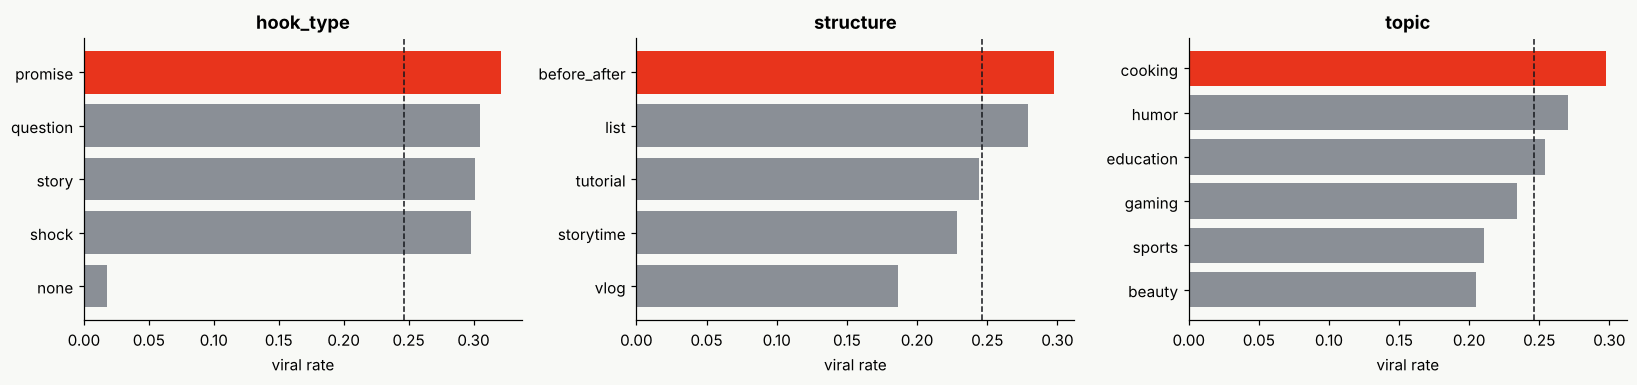

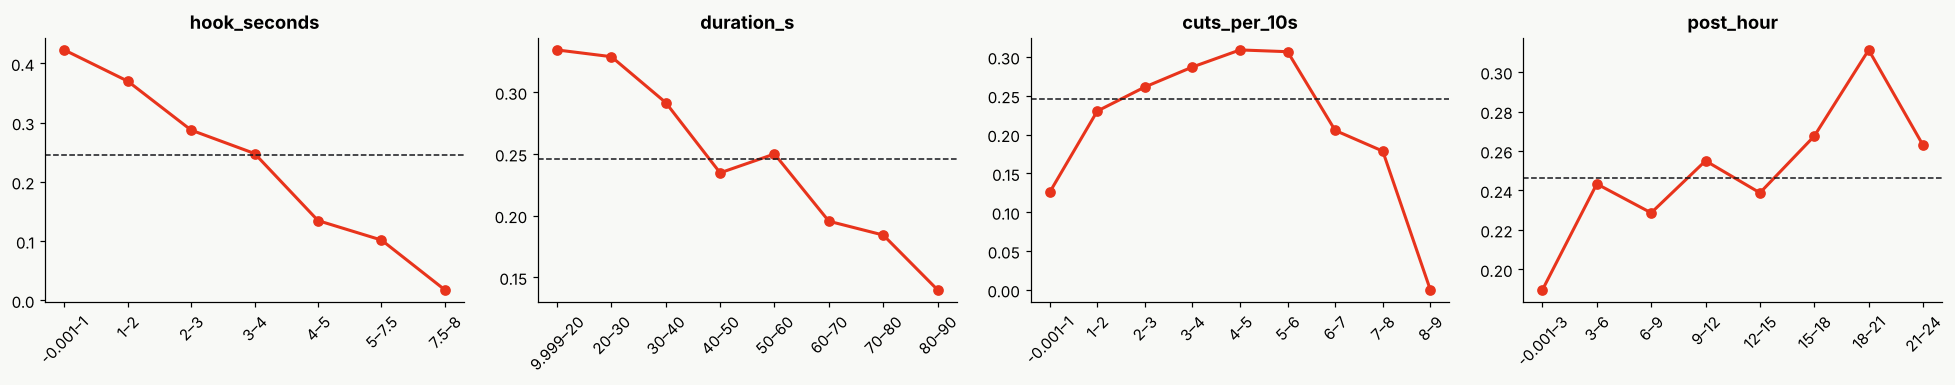

Dashed line = average viral rate in the training set


In [12]:
train = X_train.assign(viral=y_train)
rate = train.viral.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, CATEGORICAL):
    r = train.groupby(col).viral.mean().sort_values()
    ax.barh(r.index, r.values, color=[RED if v == r.max() else GREY for v in r])
    ax.axvline(rate, color=INK, ls="--", lw=1); ax.set_title(col); ax.set_xlabel("viral rate")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, col, bins in zip(axes, NUMERIC, [[0, 1, 2, 3, 4, 5, 7.5, 8], range(10, 100, 10), range(0, 10), range(0, 25, 3)]):
    r = train.groupby(pd.cut(train[col], bins, include_lowest=True), observed=True).viral.mean()
    ax.plot(range(len(r)), r.values, marker="o", color=RED, lw=2)
    ax.set_xticks(range(len(r))); ax.set_xticklabels([f"{i.left:g}–{i.right:g}" for i in r.index], rotation=45)
    ax.axhline(rate, color=INK, ls="--", lw=1); ax.set_title(col)
plt.tight_layout(); plt.show()
print("Dashed line = average viral rate in the training set")

**What the training data shows**
- **Imbalance:** only about 1 in 4 videos goes viral. A lazy intern who always answers "not viral" is already right ~75% of the time. That is the baseline to beat in Step 9.
- `hook_seconds`: the longer the hook takes, the lower the chance. Roughly a **straight line**.
- `cuts_per_10s`: an **upside-down U**. Too slow or too frantic both hurt; the best is around 3–5 cuts per 10 s.
- `duration_s`: flat at first, then falls once videos get long.
- `post_hour`: a **step** in the evening.

Only the first one is a straight line. That matters for the model in Step 8.

<a id="s8"></a>
## Step 8 — Train a Logistic Regression

> **Intern analogy: how the intern thinks.** The intern uses a **points system**. Each feature adds or removes points (a fast hook: plus points; a very long video: minus points). They add everything up and turn the total into a percentage: lots of points means "likely viral", few points means "unlikely". At the start the intern has no idea how many points each feature deserves, so every weight is 0 and they answer "50%" for everything.
>
> **How the intern learns.** They take a video from the study pile, guess, and check the answer. *"I said 20%, but it went viral. It had a loop, so maybe loops deserve more points."* They nudge the points **a little** (never a lot: one video might just have been lucky) and move to the next video. They go through the whole pile hundreds of times, and each pass their mistakes get a bit smaller. When the adjustments stop making a difference, the training is done. They only adjust the features that were **present**: if the video had no loop, the loop was not responsible, so its points stay the same.
>
> **The "boxes" trick.** A points system can only say "more X = better" or "more X = worse". But editing pace is best in the middle. So instead of one number, we sort each video into **boxes** (e.g. 0–1.3 cuts, 1.3–2.6 cuts, …) and the intern learns a separate score for each box. Now they can discover that the middle box is the best one.

**Technical note.** The model is a `Pipeline`, an assembly line that always applies the same steps in the same order:

| Stage | What it does | Why |
|---|---|---|
| `StandardScaler` on `hook_seconds` | rescales to mean 0, std 1 | that relationship is a straight line, so one weight is enough |
| `KBinsDiscretizer` on `duration_s`, `cuts_per_10s`, `post_hour` | splits each range into equal-width boxes, one 0/1 column per box | captures the U-shape and the step |
| `passthrough` on the 0/1 features | keeps them as they are | already numbers on the same scale |
| `OneHotEncoder` on categories | one 0/1 column per option | models only understand numbers |
| `LogisticRegression` | learns one weight per column | `chance = 1 / (1 + e^-(b + w₁x₁ + … + wₙxₙ))` |

The number of boxes is chosen by cross-validation on the training set (see 9.2 for what cross-validation is). The box edges, the scaler's mean and the categories are all learned **from the training set only**, inside `fit`. Training minimizes **log loss** (confident mistakes are punished much more than hesitant ones) with the L-BFGS algorithm, a refined version of gradient descent: "feel which way is downhill, take a small step, repeat". A small built-in penalty on large weights (L2 regularization, `C=1`) keeps the intern from over-reacting to odd examples.

In [13]:
def build_pipeline(model, n_boxes=6, hour_boxes=8):
    preprocess = ColumnTransformer([
        ("scale", StandardScaler(), ["hook_seconds"]),
        ("boxes", KBinsDiscretizer(n_bins=n_boxes, encode="onehot-dense", strategy="uniform"), ["duration_s", "cuts_per_10s"]),
        ("hour", KBinsDiscretizer(n_bins=hour_boxes, encode="onehot-dense", strategy="uniform"), ["post_hour"]),
        ("binary", "passthrough", BINARY),
        ("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ])
    return Pipeline([("preprocess", preprocess), ("model", model)])

# How many boxes? Decided with 5-fold cross-validation on the TRAINING set (never the test set).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
options = {}
for n_boxes, hour_boxes in [(4, 6), (6, 8), (8, 8)]:
    candidate = build_pipeline(LogisticRegression(max_iter=1000), n_boxes, hour_boxes)
    options[(n_boxes, hour_boxes)] = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    print(f"{n_boxes} boxes for duration/cuts, {hour_boxes} for hour → cross-validated AUC {options[(n_boxes, hour_boxes)]:.3f}")
N_BOXES, HOUR_BOXES = max(options, key=options.get)
print(f"Chosen: {N_BOXES} and {HOUR_BOXES} boxes\n")

pipeline = build_pipeline(LogisticRegression(max_iter=1000), N_BOXES, HOUR_BOXES)
pipeline.fit(X_train, y_train)          # ← the training happens here

log_reg = pipeline.named_steps["model"]
print(f"Trained: {log_reg.coef_.shape[1]} weights + 1 intercept (b = {log_reg.intercept_[0]:.2f}), "
      f"converged in {log_reg.n_iter_[0]} iterations")

4 boxes for duration/cuts, 6 for hour → cross-validated AUC 0.788


6 boxes for duration/cuts, 8 for hour → cross-validated AUC 0.796


8 boxes for duration/cuts, 8 for hour → cross-validated AUC 0.789
Chosen: 6 and 8 boxes

Trained: 41 weights + 1 intercept (b = -2.31), converged in 23 iterations


### 8.1 What the intern learned
Each bar is a weight. Red adds points (raises the chance), grey removes points.

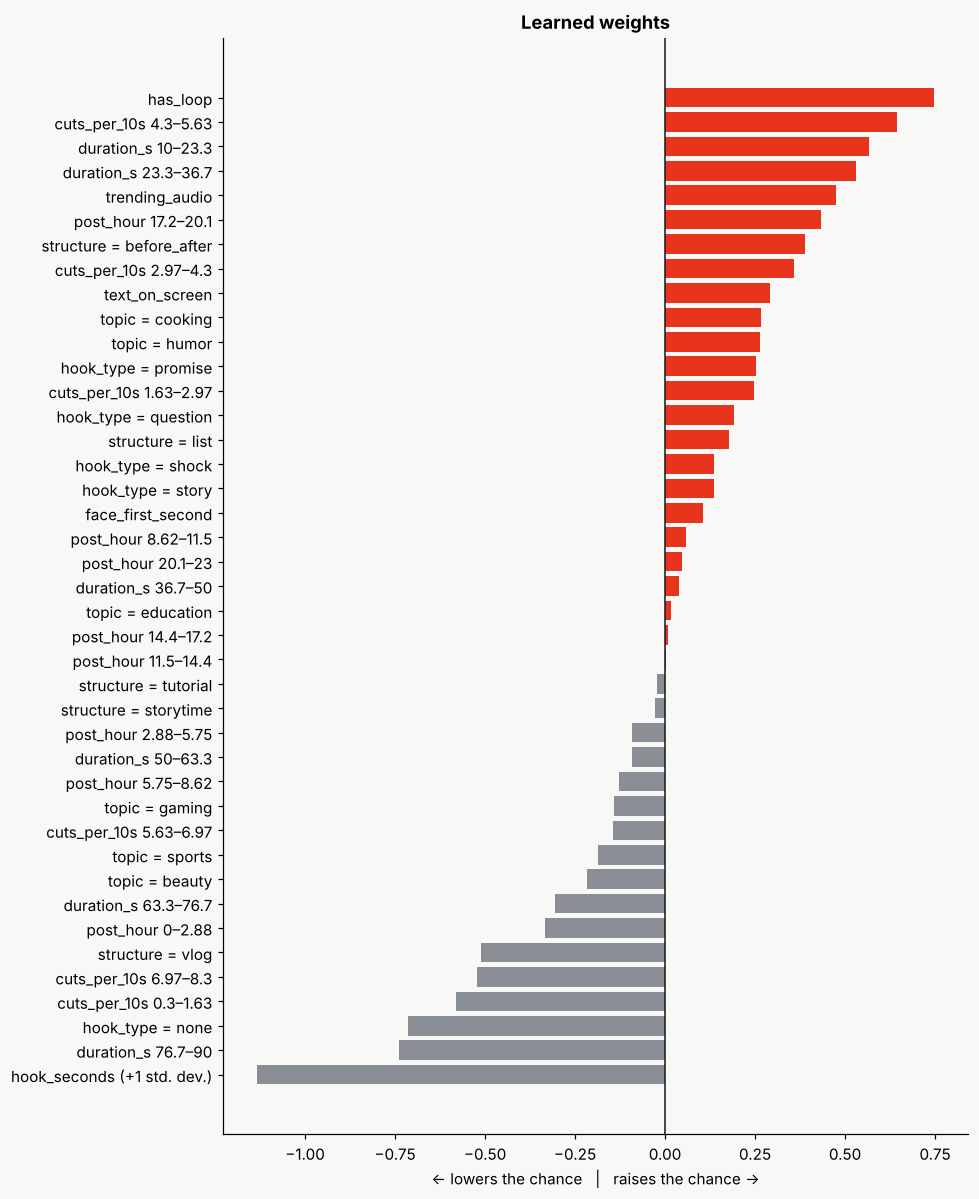

In [14]:
def readable_names(preprocess):
    names = []
    for name, step, cols in preprocess.transformers_:
        if name == "scale":
            names += [f"{c} (+1 std. dev.)" for c in cols]
        elif name in ("boxes", "hour"):
            for c, edges in zip(cols, step.bin_edges_):
                names += [f"{c} {edges[i]:.3g}–{edges[i + 1]:.3g}" for i in range(len(edges) - 1)]
        elif name == "binary":
            names += list(cols)
        elif name == "onehot":
            for c, cats in zip(cols, step.categories_):
                names += [f"{c} = {k}" for k in cats]
    return names

names = readable_names(pipeline.named_steps["preprocess"])
assert len(names) == log_reg.coef_.shape[1]
weights = pd.Series(log_reg.coef_[0], index=names).sort_values()

fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(weights.index, weights.values, color=[RED if v > 0 else GREY for v in weights.values])
ax.axvline(0, color=INK, lw=1)
ax.set_title("Learned weights"); ax.set_xlabel("← lowers the chance   |   raises the chance →")
plt.tight_layout(); plt.show()

**Did the intern rediscover the hidden rules from Step 3.1?**
- `hook_seconds` is negative: the later the hook, the lower the chance.
- `hook_type = none` and `structure = vlog` are the most negative categories.
- `has_loop`, `trending_audio` and `text_on_screen` are positive.
- The middle boxes of `cuts_per_10s` score higher than the extremes: the upside-down U was learned.
- The long-duration boxes are negative, and the evening box of `post_hour` is positive.

Nobody gave the model these rules. It found them in 2,400 noisy examples.

<a id="s9"></a>
## Step 9 — Evaluate: accuracy and confusion matrix

> **Intern analogy.** Time to open the drawer. The intern guesses each of the 600 hidden videos and we grade the answers. To know whether the grade is actually good, we compare it with the **lazy intern** who always answers "not viral".

In [15]:
pred = pipeline.predict(X_test)
proba = pipeline.predict_proba(X_test)[:, 1]

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
accuracy = accuracy_score(y_test, pred)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
precision, recall, auc = precision_score(y_test, pred), recall_score(y_test, pred), roc_auc_score(y_test, proba)

print(f"Accuracy of the model:                    {accuracy:.1%}  ({(pred == y_test).sum()} of {len(y_test)} correct)")
print(f"Accuracy of 'always says not viral':      {baseline_accuracy:.1%}")
print(f"Precision: {precision:.1%}   Recall: {recall:.1%}   AUC: {auc:.3f}")

Accuracy of the model:                    75.7%  (454 of 600 correct)
Accuracy of 'always says not viral':      75.3%
Precision: 51.2%   Recall: 29.1%   AUC: 0.801


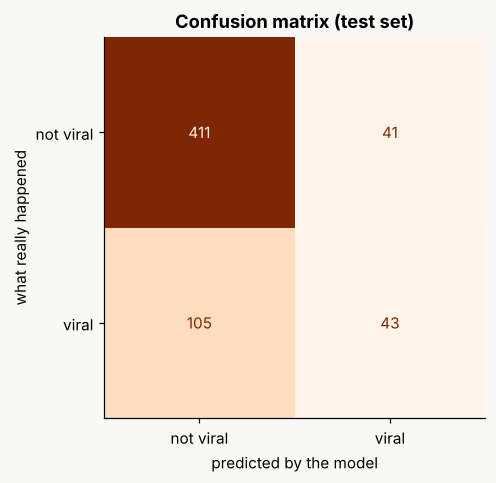

True negatives:   411  not viral, and the model said not viral
False positives:   41  false alarm
False negatives:  105  viral, but the model missed it
True positives:    43  viral, and the model caught it


In [16]:
matrix = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(matrix, display_labels=["not viral", "viral"]).plot(ax=ax, cmap="Oranges", colorbar=False)
ax.set_xlabel("predicted by the model"); ax.set_ylabel("what really happened"); ax.set_title("Confusion matrix (test set)")
plt.show()

(tn, fp), (fn, tp) = matrix
print(f"True negatives:  {tn:4d}  not viral, and the model said not viral")
print(f"False positives: {fp:4d}  false alarm")
print(f"False negatives: {fn:4d}  viral, but the model missed it")
print(f"True positives:  {tp:4d}  viral, and the model caught it")

| Metric | Question it answers |
|---|---|
| **Accuracy** | out of all test videos, what % did the model get right? |
| **Precision** | when the model says "viral", how often is it right? |
| **Recall** | out of the videos that really went viral, how many did the model catch? |
| **AUC** | given one viral and one non-viral video at random, how often does the model score the viral one higher? (0.5 = coin flip, 1.0 = perfect) |

**Reading the result.** Accuracy alone is misleading here, because the lazy intern already scores ~75% by never predicting "viral". On this particular test set the model's accuracy is only slightly above that, and the cross-validation in 9.2 (77–78% over five different splits) is a more stable estimate. The real evidence of learning is elsewhere: precision is about double the ~25% you would get by guessing, and AUC is around 0.8, far above the 0.5 of a coin flip. The 50% threshold also makes the model cautious (see 9.1). It cannot reach 100%: the data contains a luck factor, and no checklist can predict luck.

### 9.1 The decision threshold
> **Intern analogy.** The intern gives a percentage, and *we* decide from which percentage they should shout "viral!". A cautious intern (50%) rarely raises false alarms but misses many hits. A bolder one (30%) catches more viral videos, with more false alarms.

In [17]:
rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba >= threshold).astype(int)
    rows.append({"threshold": f"{threshold:.0%}", "accuracy": accuracy_score(y_test, p),
                 "precision": precision_score(y_test, p, zero_division=0), "recall": recall_score(y_test, p)})
pd.DataFrame(rows).set_index("threshold").style.format("{:.1%}")

,accuracy,precision,recall
threshold,,,
20%,65.2%,40.6%,88.5%
30%,73.8%,48.0%,73.0%
40%,75.0%,49.3%,50.0%
50%,75.7%,51.2%,29.1%
60%,77.5%,66.7%,17.6%


### 9.2 Was it luck? Cross-validation and a second opinion
> **Intern analogy.** One exam could have been unusually easy. So we run 5 mini-exams, each time hiding a different fifth of the study pile, and check that the grades are consistent.

In [18]:
scores = cross_val_score(build_pipeline(LogisticRegression(max_iter=1000), N_BOXES, HOUR_BOXES), X_train, y_train, cv=cv, scoring="accuracy")
print(f"5-fold cross-validation accuracy: {scores.mean():.1%} ± {scores.std():.1%}   {np.round(scores, 3)}")

5-fold cross-validation accuracy: 77.6% ± 1.3%   [0.777 0.779 0.767 0.76  0.798]


<a id="s10"></a>
## Step 10 — Test with completely new data

> **Intern analogy.** The real job: videos that **have not been posted yet**. There is no answer to check, only the intern's prediction. This is what the model is for.

These posts were written by hand and are not part of the 3,000. They have no `views` or `followers`, because they have not been published.

In [19]:
new_posts = [
    {"id": "new_01", "platform": "tiktok", "caption": "Before and after: my bedroom in one day #humor #comedy",
     "transcript": "[00:00.6] STOP EVERYTHING! Look at this bedroom\n[00:04.0] Yeah.\n[00:09.5] Thanks for watching.",
     "visual_notes": "opens with a close-up of a face; big text on screen at the start; the ending loops back to the start; uses a trending sound; edited with 9 cuts",
     "duration_s": 21, "posted_at": "2026-11-13T19:30"},
    {"id": "new_02", "platform": "shorts", "caption": "Vlog: my whole Sunday #football #sports",
     "transcript": "[00:00.0] Hey guys.\n[00:03.1] Then I started.\n[00:08.0] Here's how it turned out.",
     "visual_notes": "opens on the scenery; no text on screen; original audio; edited with 6 cuts",
     "duration_s": 80, "posted_at": "2026-11-15T09:10"},
    {"id": "new_03", "platform": "reels", "caption": "How to make skillet cheese bread #recipe #cooking",
     "transcript": "[00:00.0] Okay, let's go.\n[00:01.4] I'll show you the fastest cheese bread ever\n[00:05.0] Here's how it turned out.",
     "visual_notes": "a face appears in the first second; caption written over the video; original audio; edited with 14 cuts",
     "duration_s": 35, "posted_at": "2026-11-14T12:00"},
    {"id": "new_04", "platform": "shorts", "caption": "Top 5: hidden secrets of the new map #gaming #gamer",
     "transcript": "[00:00.0] Okay, let's go.\n[00:01.6] So.\n[00:03.4] Did you know you can walk through this wall?\n[00:09.0] Comment below.",
     "visual_notes": "no one on screen in the first seconds; big text on screen at the start; viral audio of the moment; edited with 24 cuts",
     "duration_s": 48, "posted_at": "2026-11-19T15:40"},
]
with open("new_posts.json", "w", encoding="utf-8") as f:
    json.dump(new_posts, f, ensure_ascii=False, indent=1)

X_new = pd.DataFrame([extract(p) for p in new_posts])[FEATURES]
result = X_new.assign(chance_viral=pipeline.predict_proba(X_new)[:, 1])
result["prediction"] = np.where(result.chance_viral >= 0.5, "VIRAL", "not viral")
result.insert(0, "id", [p["id"] for p in new_posts])
result.style.format({"chance_viral": "{:.1%}"})

,id,hook_seconds,duration_s,cuts_per_10s,post_hour,face_first_second,text_on_screen,has_loop,trending_audio,hook_type,structure,topic,chance_viral,prediction
0,new_01,0.600000,21.000000,4.300000,19,1,1,1,1,shock,before_after,humor,95.3%,VIRAL
1,new_02,8.000000,80.000000,0.800000,9,0,0,0,0,none,vlog,sports,0.1%,not viral
2,new_03,1.400000,35.000000,4.000000,12,1,1,0,0,promise,tutorial,cooking,60.0%,VIRAL
3,new_04,3.400000,48.000000,5.000000,15,0,1,0,1,question,list,gaming,36.8%,not viral


> **Try it:** change one thing in `new_04` (e.g. move the hook to `[00:00.8]`, or add *"the ending loops back to the start"* to its visual notes) and run the cell again to see how much that single change is worth.

<a id="s11"></a>
## Step 11 — Export the trained model as `.pkl`

> **Intern analogy.** Training took effort, and you do not want the intern to study from scratch every time. So you write down everything they learned (every weight, every box edge, every category) in a **notebook they can take anywhere**. That notebook is the `.pkl` file.

**Technical note.** `pickle` turns the whole `Pipeline` (preprocessing + weights) into a file. The pipeline contains only standard scikit-learn components, so opening it needs nothing but scikit-learn. Some metadata is saved with it, including the scikit-learn version, because a `.pkl` should be opened with the same version that created it. It also stores a little extra information (the average of each column in the training data) so the app can explain *why* a video got its score.

In [20]:
def source_feature_of_each_column(preprocess):
    sources = []
    for name, step, cols in preprocess.transformers_:
        if name in ("scale", "binary"):
            sources += list(cols)
        elif name in ("boxes", "hour"):
            for c, n in zip(cols, step.n_bins_):
                sources += [c] * int(n)
        elif name == "onehot":
            for c, cats in zip(cols, step.categories_):
                sources += [c] * len(cats)
    return sources

train_matrix = pipeline.named_steps["preprocess"].transform(X_train)
train_matrix = train_matrix.toarray() if hasattr(train_matrix, "toarray") else np.asarray(train_matrix)

bundle = {
    "name": "Will It Go Viral? — Logistic Regression",
    "author": "Gustavo Pugliezi",
    "pipeline": pipeline,
    "features": FEATURES,
    "threshold": 0.5,
    "trained_on": len(X_train),
    "test_accuracy": float(accuracy),
    "sklearn_version": sklearn.__version__,
    # used by predict_app.py to explain a prediction ("what helped, what hurt")
    "column_source": source_feature_of_each_column(pipeline.named_steps["preprocess"]),
    "column_means": train_matrix.mean(axis=0),
    "average_chance": float(pipeline.predict_proba(X_train)[:, 1].mean()),
}
with open("viral_model.pkl", "wb") as f:
    pickle.dump(bundle, f)
print(f"Saved viral_model.pkl ({os.path.getsize('viral_model.pkl') / 1024:.1f} KB)")

Saved viral_model.pkl (5.4 KB)


<a id="s12"></a>
## Step 12 — Open and run in any application

> **Intern analogy.** Now anyone can borrow the intern's notebook and make the same predictions, without any studying. We prove it twice: first by reopening the file from scratch, then with a completely separate program.

### 12.1 Reopening the `.pkl` from scratch

In [21]:
with open("viral_model.pkl", "rb") as f:
    loaded = pickle.load(f)

assert np.allclose(loaded["pipeline"].predict_proba(X_test)[:, 1], proba)
print(f"{loaded['name']} | by {loaded['author']} | test accuracy {loaded['test_accuracy']:.1%}")
print("Predictions are identical to the original model ✔")

Will It Go Viral? — Logistic Regression | by Gustavo Pugliezi | test accuracy 75.7%
Predictions are identical to the original model ✔


### 12.2 A separate command-line application
`predict_app.py` is an independent program that anyone can run from a terminal. It only needs `viral_model.pkl` and `post_extractor.py` next to it. It has two modes:

| Command | What it does |
|---|---|
| `python predict_app.py` | **asks questions about your video** and predicts its chance of going viral |
| `python predict_app.py new_posts.json` | predicts every post in a JSON file |

> **Intern analogy.** Anyone can borrow the intern's notebook, answer the 11-question checklist for *their own* video, and get the intern's opinion, with a short explanation of what helped and what hurt. They do not need to study anything, and they do not need Python skills.

In [22]:
%%writefile predict_app.py
"""Predicts whether a short video will go viral, using viral_model.pkl.

Usage:
    python predict_app.py                    asks questions about YOUR video
    python predict_app.py posts.json         predicts every post in a JSON file
    python predict_app.py posts.json --llm   same, but an LLM reads the posts (needs ANTHROPIC_API_KEY)
"""
import json
import pickle
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

import post_extractor as px

HERE = Path(__file__).resolve().parent

HOOK_TYPES = [("question", 'Question      ("Did you know...?")'), ("shock", 'Shock         ("STOP EVERYTHING!")'),
              ("promise", 'Promise       ("I\'ll show you...")'), ("story", 'Story         ("Let me tell you...")'),
              ("none", "No hook, it starts slowly")]
STRUCTURES = [("list", 'List          ("3 things about...", "Top 5")'), ("tutorial", 'Tutorial      ("How to...")'),
              ("before_after", "Before and after"), ("storytime", "Storytime"), ("vlog", "Vlog / a day in my life")]
TOPICS = [("humor", "Humor"), ("education", "Education"), ("beauty", "Beauty"),
          ("gaming", "Gaming"), ("cooking", "Cooking"), ("sports", "Sports")]
LABELS = {"hook_seconds": "hook timing", "hook_type": "hook type", "face_first_second": "face in the first second",
          "text_on_screen": "text on screen", "duration_s": "duration", "cuts_per_10s": "editing pace",
          "structure": "format", "has_loop": "loop ending", "topic": "topic", "trending_audio": "trending audio",
          "post_hour": "posting hour"}


def load_model(path=HERE / "viral_model.pkl"):
    with open(path, "rb") as f:
        bundle = pickle.load(f)
    if bundle["sklearn_version"] != sklearn.__version__:
        warnings.warn(f"model saved with scikit-learn {bundle['sklearn_version']}, running {sklearn.__version__}")
    return bundle


def predict(posts, bundle, use_llm=False):
    """Mode 2: posts written as JSON (caption, transcript, visual notes...)."""
    extract = px.extract_with_llm if use_llm else px.extract_simulated
    X = pd.DataFrame([extract(p) for p in posts])[bundle["features"]]
    chances = bundle["pipeline"].predict_proba(X)[:, 1]
    return [(p.get("id", "?"), float(c), c >= bundle["threshold"]) for p, c in zip(posts, chances)]


# ---------------------------------------------------------------- mode 1: questions
def ask(prompt):
    raw = input(prompt + " ").strip()
    if not sys.stdin.isatty():
        print(raw)   # when answers come from a pipe, echo them so the output reads like a conversation
    return raw


def ask_number(prompt, low, high, integer=False):
    while True:
        raw = ask(prompt).replace(",", ".")
        try:
            value = float(raw)
        except ValueError:
            print(f"  Please type a number between {low} and {high}.")
            continue
        if not low <= value <= high:
            print(f"  Please type a number between {low} and {high}.")
        elif integer and value != int(value):
            print("  Please type a whole number.")
        else:
            return int(value) if integer else value


def ask_yes_no(prompt):
    while True:
        raw = ask(prompt + " (y/n)").lower()
        if raw in ("y", "yes", "s", "sim"):
            return 1
        if raw in ("n", "no", "nao", "não"):
            return 0
        print("  Please type y or n.")


def ask_choice(prompt, options):
    print(prompt)
    for number, (_, label) in enumerate(options, 1):
        print(f"  {number}) {label}")
    while True:
        raw = ask("  Type the number:")
        if raw.isdigit() and 1 <= int(raw) <= len(options):
            return options[int(raw) - 1][0]
        print(f"  Please type a number from 1 to {len(options)}.")


def ask_about_video():
    print("Answer a few questions about your video.\n")
    duration = ask_number("1. How long is the video, in seconds?", 3, 600)
    if not 10 <= duration <= 90:
        print("   Note: the model learned from videos of 10 to 90 s, so the result is less reliable.")
    cuts = ask_number("2. How many cuts (scene changes) does it have?", 0, 500, integer=True)
    pace = round(cuts / duration * 10, 1)
    if not 0.5 <= pace <= 8:
        print(f"   Note: that is {pace} cuts per 10 s; the model saw 0.5 to 8, so the result is less reliable.")
    hook_type = ask_choice("3. What kind of hook opens the video?", HOOK_TYPES)
    hook_seconds = 8.0 if hook_type == "none" else ask_number("4. At which second does the hook sentence start?", 0, 60)
    return {
        "hook_seconds": hook_seconds,
        "hook_type": hook_type,
        "face_first_second": ask_yes_no("5. Does a face appear in the first second?"),
        "text_on_screen": ask_yes_no("6. Is there written text on screen at the start?"),
        "duration_s": duration,
        "cuts_per_10s": pace,
        "structure": ask_choice("7. What is the format?", STRUCTURES),
        "has_loop": ask_yes_no("8. Does the ending loop back to the beginning?"),
        "topic": ask_choice("9. What is the topic?", TOPICS),
        "trending_audio": ask_yes_no("10. Does it use a trending sound?"),
        "post_hour": ask_number("11. At what hour will it be posted? (0-23)", 0, 23, integer=True),
    }


def explain(features, bundle):
    """Points each feature added or removed compared with an average training video."""
    pipeline = bundle["pipeline"]
    x = pipeline.named_steps["preprocess"].transform(pd.DataFrame([features])[bundle["features"]])
    x = x.toarray() if hasattr(x, "toarray") else np.asarray(x)
    points = pipeline.named_steps["model"].coef_[0] * (x[0] - bundle["column_means"])
    by_feature = {}
    for source, value in zip(bundle["column_source"], points):
        by_feature[source] = by_feature.get(source, 0.0) + float(value)
    return sorted(by_feature.items(), key=lambda item: item[1])


def show_result(features, bundle):
    chance = float(bundle["pipeline"].predict_proba(pd.DataFrame([features])[bundle["features"]])[0, 1])
    verdict = "VIRAL" if chance >= bundle["threshold"] else "not viral"
    print("\n" + "=" * 52)
    print(f"Chance of going viral: {chance:.1%}   {'█' * round(chance * 20):<20s}  →  {verdict}")
    print(f"(an average video in the training data has about {bundle['average_chance']:.0%})")
    print("=" * 52)
    ranking = explain(features, bundle)
    helped = [(n, p) for n, p in reversed(ranking) if p > 0.05][:3]
    hurt = [(n, p) for n, p in ranking if p < -0.05][:3]
    if helped:
        print("\nWhat helped:")
        for name, points in helped:
            print(f"  + {LABELS[name]:26s} {points:+.2f} points")
    if hurt:
        print("\nWhat hurt:")
        for name, points in hurt:
            print(f"  - {LABELS[name]:26s} {points:+.2f} points")
    print("\nTip: run it again changing one answer to see how much that single choice is worth.")


if __name__ == "__main__":
    args = [a for a in sys.argv[1:] if not a.startswith("--")]
    bundle = load_model()
    print(f"{bundle['name']} (trained on {bundle['trained_on']} videos)\n")
    try:
        if not args:
            show_result(px.validate_features(ask_about_video()), bundle)
        else:
            posts = json.loads(Path(args[0]).read_text(encoding="utf-8"))
            for post_id, chance, viral in predict(posts, bundle, use_llm="--llm" in sys.argv):
                print(f"{post_id:10s} {chance:6.1%}  {'█' * round(chance * 20):20s}  {'VIRAL' if viral else 'not viral'}")
    except (EOFError, KeyboardInterrupt):
        print("\nStopped.")
    except ValueError as error:
        sys.exit(f"Problem with the information given: {error}")

Writing predict_app.py


**Mode 2: posts from a JSON file** (the same format as Step 3, here the 4 posts of Step 10):

In [23]:
!"{sys.executable}" predict_app.py new_posts.json

Will It Go Viral? — Logistic Regression (trained on 2400 videos)



new_01      95.3%  ███████████████████   VIRAL
new_02       0.1%                        not viral
new_03      60.0%  ████████████          VIRAL
new_04      36.8%  ███████               not viral


### 12.3 Testing your own video, from the terminal

Open a terminal in the folder that contains `viral_model.pkl`, `post_extractor.py` and `predict_app.py` (they were created by the cells above), and run:
```bash
python predict_app.py
```
The program asks 11 questions, one at a time, and prints the chance of going viral and what helped or hurt. Anyone can do this with a copy of those three files and Python with `pandas` and `scikit-learn` installed. No notebook needed.

The cell below does the same thing automatically, answering the questions for an example video, so you can see what the conversation looks like:

In [24]:
import subprocess

example_answers = ["25",   # 1. duration (s)
                   "10",   # 2. number of cuts
                   "2",    # 3. hook type: shock
                   "1",    # 4. hook starts at second 1
                   "y",    # 5. face in the first second
                   "y",    # 6. text on screen
                   "3",    # 7. format: before and after
                   "y",    # 8. loop ending
                   "1",    # 9. topic: humor
                   "y",    # 10. trending sound
                   "19"]   # 11. posting hour
demo = subprocess.run([sys.executable, "predict_app.py"], input="\n".join(example_answers) + "\n",
                      text=True, capture_output=True)
print(demo.stdout or demo.stderr)

Will It Go Viral? — Logistic Regression (trained on 2400 videos)

Answer a few questions about your video.

1. How long is the video, in seconds? 25
2. How many cuts (scene changes) does it have? 10
3. What kind of hook opens the video?
  1) Question      ("Did you know...?")
  2) Shock         ("STOP EVERYTHING!")
  3) Promise       ("I'll show you...")
  4) Story         ("Let me tell you...")
  5) No hook, it starts slowly
  Type the number: 2
4. At which second does the hook sentence start? 1
5. Does a face appear in the first second? (y/n) y
6. Is there written text on screen at the start? (y/n) y
7. What is the format?
  1) List          ("3 things about...", "Top 5")
  2) Tutorial      ("How to...")
  3) Before and after
  4) Storytime
  5) Vlog / a day in my life
  Type the number: 3
8. Does the ending loop back to the beginning? (y/n) y
9. What is the topic?
  1) Humor
  2) Education
  3) Beauty
  4) Gaming
  5) Cooking
  6) Sports
  Type the number: 1
10. Does it use a trendi

---
## Summary

In [25]:
summary = pd.Series({
    "Posts received (JSON)": f"{len(posts):,}",
    "Features per video": len(FEATURES),
    "Training / testing videos": f"{len(X_train):,} / {len(X_test):,}",
    "Accuracy (test)": f"{accuracy:.1%}",
    "Accuracy of 'always not viral'": f"{baseline_accuracy:.1%}",
    "Precision / Recall": f"{precision:.1%} / {recall:.1%}",
    "AUC": f"{auc:.3f}",
    "Cross-validation accuracy": f"{scores.mean():.1%} ± {scores.std():.1%}",
    "Exported model": "viral_model.pkl",
}, name="")
summary.to_frame()

,
Posts received (JSON),"3,000"
Features per video,11
Training / testing videos,"2,400 / 600"
Accuracy (test),75.7%
Accuracy of 'always not viral',75.3%
Precision / Recall,51.2% / 29.1%
AUC,0.801
Cross-validation accuracy,77.6% ± 1.3%
Exported model,viral_model.pkl


### In one sentence
> We showed an "intern" 2,400 example videos; it learned how many points each characteristic is worth, and on 600 videos it had never seen it ranked viral videos above non-viral ones about 80% of the time (AUC ≈ 0.8), discovering by itself that **the hook, the length and the editing pace** matter most.

### Quality checks built into this notebook
| Risk | How it is handled |
|---|---|
| **Answer leaking into the features** | the extractor only sees `VISIBLE_FIELDS`; `views` and `followers` are used for the label only |
| **Peeking at the exam** | exploration (7.1) uses the training set only; box edges, scaler and categories are learned inside `fit` on training data |
| **Silent bad data** | `validate_features` rejects unknown categories, missing values and out-of-range numbers |
| **Lucky split** | 5-fold cross-validation |
| **Broken export** | the reloaded `.pkl` is checked to give identical predictions; the app warns about version mismatches |
| **Reproducibility** | a fixed random seed |

### Limitations
1. **The data is simulated.** The model learned rules that were written into the generator. To make real-world claims, real posts would have to be annotated; the notebook would work unchanged with a real `posts.json`.
2. **Correlation is not causation.** Even with real data, "videos with loops go viral more often" would not prove that adding a loop *causes* virality.
3. **Missing factors.** Platform algorithms, trends and the quality of the idea itself are not in the checklist, which is why some of the outcome is unpredictable luck.
4. **Extraction errors.** An LLM can mis-measure a feature. With real data, a sample of its answers should be checked by a person.